Inainte sa trimiti notebook-ul:

* asigura-te ca totul se executa cum trebuie. Prima oara, **restarteaza kernel-ul** (in meniu, selecteaza Kernel$\rightarrow$Restart & Run all);

* nu lasa niciun mesaj la output (`disp`, `printf`, linii care nu sunt incheiate cu `;`) in functiile pe care le scrii decat daca ti se specifica explicit sa faci acest lucru! Orice abatere va fi **depunctata automat** de grader;

* citeste instructiunile de [aici](https://github.com/radusqrt/numerical-methods/blob/master/lab_instructions.md) cu atentie;

* asigura-te ca rezolvi toate celulele in care scrie `YOUR CODE HERE` sau `YOUR ANSWER HERE` si ca iti treci numele mai jos:

In [1]:
STUDENT_NAME = "Ionescu Andrei";

---

# Laborator 10: DFT si FFT
### Autor: Radu Stochitoiu

## Problema 1

Implementati funcția ```create_fourier_matrix(N)``` ce primește $N$, numărul de sample-uri, și returnează matricea F pentru DFT.

In [2]:
function [F] = create_fourier_matrix(N)
    omega = exp(2 * pi * i / N);
    F = omega .^ [0:N-1]';
    F = F .^ [0:N-1]';
endfunction

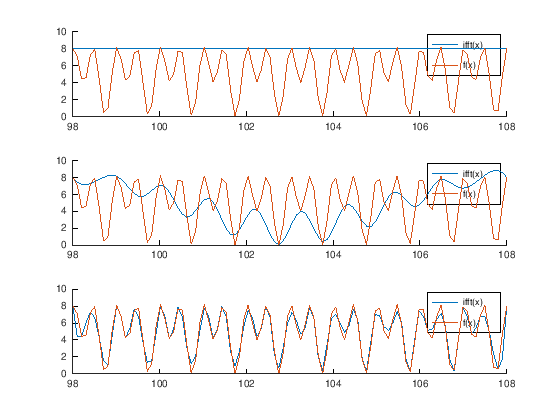

In [3]:
function [y] = f(t)
    y = 5 + 2 * cos(2 * pi * t - pi/2) + 3 * cos(4 * pi * t);
endfunction

% Test 1
N = 5;
ref = dlmread("create_fourier_matrix_5.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 1);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 2
N = 20;
ref = dlmread("create_fourier_matrix_20.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 2);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 3
N = 50;
ref = dlmread("create_fourier_matrix_50.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 3);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

## Problema 2

Implementati funcția ```create_fft_matrix(N)``` ce primește $N$, numărul de sample-uri, și returnează matricea F pentru DFT construită cu ajutorul FFT.

In [4]:
function [F] = create_fft_matrix(N)
    M = N/2;
    
    omega = exp(2 * pi * i / N);
    D = diag(omega .^ [0:M-1]);
    I = eye(M);
    
    F = create_fourier_matrix(M);
    
    perm = zeros(N);
    perm(sub2ind([N, N], [1:N], [1:2:N, 2:2:N])) = 1;
    
    F = [I, D; I, -D] * blkdiag(F, F) * perm;
endfunction

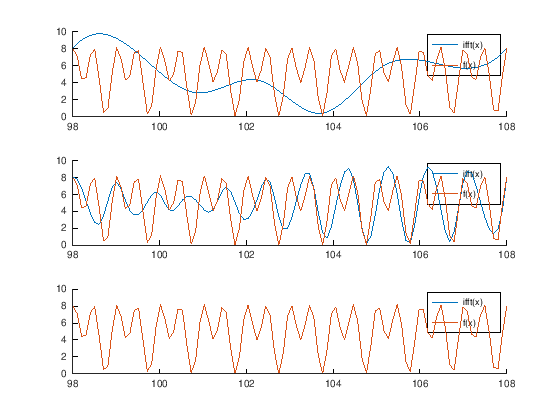

In [5]:
function [y] = f(t)
    y = 5 + 2 * cos(2 * pi * t - pi/2) + 3 * cos(4 * pi * t);
endfunction

% Test 1
N = 8;
ref = dlmread("create_fft_matrix_8.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 1);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 2
N = 32;
ref = dlmread("create_fft_matrix_32.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 2);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 3
N = 256;
ref = dlmread("create_fft_matrix_256.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 3);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");